In [1]:
from pathlib import Path
from urllib.request import urlopen
from IPython.display import display, Markdown, Image

url = "https://raw.githubusercontent.com/hwngchimung/midterm2-group1/main/laptop_midterm2/data/raw/laptop_price.csv"

DATA_PATH = Path('laptop_price.csv')
with urlopen(url, timeout=60) as response:
    DATA_PATH.write_bytes(response.read())

OUTPUT = Path('laptop_outputs')
OUTPUT.mkdir(exist_ok=True)
print('Data:', DATA_PATH.name)


Data: laptop_price.csv


### Thư viện và cấu hình

In [2]:
"""
Phân tích đề 6 - Laptop Price. Chạy từ thư mục gốc của dự án
python src/laptop_analysis.py
Không thay đổi dữ liệu gốc. Các đầu ra được tái tạo trong reports và data/processed
"""
from pathlib import Path
import hashlib
import json
import re
import platform

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

SOURCE_URL = "https://www.kaggle.com/datasets/muhammetvarl/laptop-price"
ALPHA = 0.05
SEED = 42
NUMERIC_FEATURES = ["Ram_GB", "Weight_kg", "Inches", "PPI", "Cpu_GHz", "SSD_GB", "HDD_GB", "Price_euros"]

### Hàm đánh giá dữ liệu

In [3]:
def audit_raw(raw):
    schema = pd.DataFrame({
        "field": raw.columns,
        "dtype": [str(raw[c].dtype) for c in raw],
        "missing": [int(raw[c].isna().sum()) for c in raw],
        "missing_pct": [float(raw[c].isna().mean() * 100) for c in raw],
        "blank_strings": [int(raw[c].astype(str).str.strip().eq("").sum()) for c in raw],
        "unique_values": [int(raw[c].nunique()) for c in raw],
    })
    key = [c for c in raw if c != "laptop_ID"]
    audit = {
        "raw_rows": len(raw), "raw_columns": len(raw.columns),
        "missing_cells": int(raw.isna().sum().sum()),
        "blank_strings": int(schema.blank_strings.sum()),
        "duplicate_ids": int(raw.laptop_ID.duplicated().sum()),
        "exact_duplicate_rows": int(raw.duplicated().sum()),
        "duplicates_without_id": int(raw.duplicated(subset=key).sum()),
    }
    return schema, audit

### Hàm làm sạch và tách đơn vị

In [4]:
def parse_memory(text):
    result = {"SSD_GB": 0.0, "HDD_GB": 0.0, "Flash_GB": 0.0, "Hybrid_GB": 0.0}
    names = {"SSD": "SSD_GB", "HDD": "HDD_GB", "Flash Storage": "Flash_GB", "Hybrid": "Hybrid_GB"}
    for part in str(text).split("+"):
        match = re.fullmatch(r"\s*(\d+(?:\.\d+)?)\s*(GB|TB)\s+(SSD|HDD|Flash Storage|Hybrid)\s*", part)
        if not match:
            raise ValueError(f"Không tách được Memory: {text!r}")
        size, unit, kind = match.groups()
        result[names[kind]] += float(size) * (1000 if unit == "TB" else 1)
    return result


def clean_data(raw, deduplicate=True):
    """Chuẩn hóa đơn vị, tách cấu hình; giữ nguyên các trường gốc để đối chiếu"""
    df = raw.copy(deep=True)
    for c in df.columns:
        if pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c]):
            df[c] = df[c].str.strip()
    if deduplicate:
        # Một quan sát là bản ghi cấu hình-giá, không phải giao dịch hay số máy bán
        df = df.drop_duplicates(subset=[c for c in raw if c != "laptop_ID"]).copy()
    df = df.reset_index(drop=True)
    df["Ram_GB"] = pd.to_numeric(df.Ram.str.extract(r"^(\d+)GB$", expand=False), errors="raise")
    df["Weight_kg"] = pd.to_numeric(df.Weight.str.extract(r"^(\d+(?:\.\d+)?)kg$", expand=False), errors="raise")
    resolution = df.ScreenResolution.str.extract(r"(\d+)x(\d+)")
    df["ScreenWidth_px"] = pd.to_numeric(resolution[0], errors="raise")
    df["ScreenHeight_px"] = pd.to_numeric(resolution[1], errors="raise")
    df["PPI"] = np.hypot(df.ScreenWidth_px, df.ScreenHeight_px) / df.Inches
    df["Touchscreen"] = df.ScreenResolution.str.contains("Touchscreen", case=False, regex=False)
    df["IPS"] = df.ScreenResolution.str.contains("IPS", case=False, regex=False)
    df["Cpu_GHz"] = pd.to_numeric(df.Cpu.str.extract(r"(\d+(?:\.\d+)?)GHz", expand=False), errors="raise")
    df["Cpu_brand"] = df.Cpu.str.split().str[0]
    df["Gpu_brand"] = df.Gpu.str.split().str[0]
    memory = pd.DataFrame(df.Memory.map(parse_memory).tolist(), index=df.index)
    df = pd.concat([df, memory], axis=1)
    df["Has_SSD"] = df.SSD_GB.gt(0)

    q1, q3 = df.Price_euros.quantile([0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    df["Price_IQR_flag"] = (df.Price_euros < lower) | (df.Price_euros > upper)
    required_positive = ["Price_euros", "Ram_GB", "Weight_kg", "Inches", "PPI", "Cpu_GHz"]
    if df[required_positive].isna().any().any() or not df[required_positive].gt(0).all().all():
        raise ValueError("Có giá trị thiếu hoặc không dương sau khi tách dữ liệu.")
    return df

### Hàm kiểm định và phân tích độ nhạy

In [5]:
def holm_adjust(pvalues):
    """Holm cho ba kiểm định chính, kiểm soát sai số theo họ kiểm định"""
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    adjusted[order] = np.minimum(1.0, np.maximum.accumulate(p[order] * np.arange(len(p), 0, -1)))
    return adjusted


def hypothesis_tests(df):
    """Các giả thuyết khám phá, p-value không chứng minh quan hệ nhân quả"""
    # H1: H0 rho=0; H1 rho>0 (Spearman)
    ram_test = stats.spearmanr(df.Ram_GB, df.Price_euros, alternative="greater")
    # H2: H0 hai phân phối giống nhau, H1 giá nhóm SSD có xu hướng cao hơn
    x = df.loc[df.Has_SSD, "Price_euros"]
    y = df.loc[~df.Has_SSD, "Price_euros"]
    ssd_test = stats.mannwhitneyu(x, y, alternative="greater", method="asymptotic")
    # H3: Kiểm định tổng thể sáu phân phối theo TypeName, không kết luận từng cặp
    groups = [g.Price_euros.to_numpy() for _, g in df.groupby("TypeName", sort=True)]
    if min(map(len, groups)) < 5:
        raise ValueError("Nhóm TypeName quá nhỏ cho xấp xỉ Kruskal-Wallis.")
    type_test = stats.kruskal(*groups)
    rows = [
        {"hypothesis": "H1 RAM-price", "test": "Spearman greater", "statistic": float(ram_test.statistic), "p_raw": float(ram_test.pvalue), "effect": float(ram_test.statistic), "effect_name": "Spearman rho"},
        {"hypothesis": "H2 SSD-price", "test": "Mann-Whitney greater", "statistic": float(ssd_test.statistic), "p_raw": float(ssd_test.pvalue), "effect": float(ssd_test.statistic / (len(x) * len(y))), "effect_name": "P(SSD>non-SSD)+0.5*P(tie)"},
        {"hypothesis": "H3 type-price", "test": "Kruskal-Wallis", "statistic": float(type_test.statistic), "p_raw": float(type_test.pvalue), "effect": float(max(0, (type_test.statistic - len(groups) + 1) / (len(df) - len(groups)))), "effect_name": "epsilon squared H"},
    ]
    table = pd.DataFrame(rows)
    table["p_holm"] = holm_adjust(table.p_raw)
    table["reject_H0_at_0.05"] = table.p_holm < ALPHA
    return table


def group_summary(df, field):
    """Luôn ghi cỡ mẫu để tránh suy rộng từ nhóm chỉ có vài bản ghi."""
    return df.groupby(field, observed=True).Price_euros.agg(n="size", mean="mean", median="median", minimum="min", maximum="max").reset_index()


def analyze(df):
    """Tạo thống kê và khoảng bootstrap mô tả chênh lệch trung vị SSD."""
    q1, q3 = df.Price_euros.quantile([0.25, 0.75])
    ssd = df.loc[df.Has_SSD, "Price_euros"].to_numpy()
    other = df.loc[~df.Has_SSD, "Price_euros"].to_numpy()
    rng = np.random.default_rng(SEED)

    differences = np.array([
        np.median(rng.choice(ssd, len(ssd), replace=True)) - np.median(rng.choice(other, len(other), replace=True))
        for _ in range(2000)
    ])
    return {
        "clean_rows": len(df), "companies": int(df.Company.nunique()),
        "price_mean": float(df.Price_euros.mean()), "price_median": float(df.Price_euros.median()),
        "price_min": float(df.Price_euros.min()), "price_max": float(df.Price_euros.max()),
        "price_q1": float(q1), "price_q3": float(q3), "price_skew": float(df.Price_euros.skew()),
        "iqr_lower": float(q1 - 1.5 * (q3 - q1)), "iqr_upper": float(q3 + 1.5 * (q3 - q1)),
        "iqr_flagged": int(df.Price_IQR_flag.sum()),
        "ssd_n": len(ssd), "non_ssd_n": len(other),
        "ssd_median": float(np.median(ssd)), "non_ssd_median": float(np.median(other)),
        "ssd_median_diff": float(np.median(ssd) - np.median(other)),
        "ssd_median_diff_ci95": [float(v) for v in np.quantile(differences, [0.025, 0.975])],
        "ram_rho": float(stats.spearmanr(df.Ram_GB, df.Price_euros).statistic),
        "ppi_rho": float(stats.spearmanr(df.PPI, df.Price_euros).statistic),
        "weight_rho": float(stats.spearmanr(df.Weight_kg, df.Price_euros).statistic),
    }


def sensitivity_analysis(raw, clean):
    """So sánh kết quả có trùng, bỏ trùng, và bỏ cờ IQR (chỉ đối chiếu)."""
    scenarios = {"raw_with_duplicates": clean_data(raw, False), "deduplicated_main": clean,
                 "without_IQR_flags_sensitivity_only": clean.loc[~clean.Price_IQR_flag].copy()}
    rows = []
    for name, data in scenarios.items():
        h = hypothesis_tests(data)
        x, y = data.loc[data.Has_SSD, "Price_euros"], data.loc[~data.Has_SSD, "Price_euros"]
        rows.append({"scenario": name, "n": len(data), "median_eur": data.Price_euros.median(),
                     "ram_rho": h.loc[0, "effect"], "ssd_median_gap_eur": x.median() - y.median(),
                     "H1_p_holm": h.loc[0, "p_holm"], "H2_p_holm": h.loc[1, "p_holm"], "H3_p_holm": h.loc[2, "p_holm"]})
    return pd.DataFrame(rows)

### Hàm trực quan hóa

In [6]:
def make_figures(df, output):
    """Mỗi hình trả lời một câu hỏi, có đơn vị và cỡ mẫu trong nhãn."""
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False,
                         "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 180})
    blue, orange = "#2563a6", "#d67523"

    def save(fig, name):
        fig.savefig(output / name, bbox_inches="tight", facecolor="white")
        plt.close(fig)

    # Hình 1: Phân phối giá và cờ ngoại lệ IQR
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), constrained_layout=True)
    axes[0].hist(df.Price_euros, bins=35, color=blue, edgecolor="white")
    axes[0].axvline(df.Price_euros.mean(), color=orange, label=f"Mean = {df.Price_euros.mean():,.0f}")
    axes[0].axvline(df.Price_euros.median(), color="#333333", linestyle="--", label=f"Median = {df.Price_euros.median():,.0f}")
    axes[0].set(xlabel="Giá (EUR)", ylabel="Số bản ghi", title=f"Phân phối giá (n={len(df):,})")
    axes[0].legend(fontsize=8)
    axes[1].boxplot(df.Price_euros, vert=False, widths=0.35, patch_artist=True,
                    boxprops={"facecolor": "#bfdbfe"}, medianprops={"color": "#111827"})
    axes[1].set(xlabel="Giá (EUR)", yticks=[], title="Giá trị xa theo quy tắc 1,5 IQR")
    save(fig, "01_price_distribution.png")

    # Hình 2: RAM và giá; giữ các nhóm nhỏ nhưng hiển thị rõ n
    ram_levels = sorted(df.Ram_GB.unique())
    fig, ax = plt.subplots(figsize=(9.4, 4.3), constrained_layout=True)
    ax.boxplot([df.loc[df.Ram_GB.eq(v), "Price_euros"] for v in ram_levels], patch_artist=True,
               boxprops={"facecolor": "#bfdbfe"}, medianprops={"color": "#111827"})
    ax.set_xticks(range(1, len(ram_levels) + 1), [f"{v} GB\n(n={int(df.Ram_GB.eq(v).sum())})" for v in ram_levels])
    ax.set(xlabel="Dung lượng RAM", ylabel="Giá (EUR)", title="Giá phân bố thế nào theo RAM?")
    save(fig, "02_ram_price.png")

    # Hình 3: Có SSD bao gồm SSD đơn và SSD kết hợp ổ khác
    fig, ax = plt.subplots(figsize=(7.5, 4), constrained_layout=True)
    groups = [df.loc[~df.Has_SSD, "Price_euros"], df.loc[df.Has_SSD, "Price_euros"]]
    ax.boxplot(groups, patch_artist=True, boxprops={"facecolor": "#fed7aa"}, medianprops={"color": "#111827"})
    ax.set_xticks([1, 2], [f"Không có SSD\n(n={len(groups[0])})", f"Có SSD\n(n={len(groups[1])})"])
    ax.set(ylabel="Giá (EUR)", title="Giá theo sự hiện diện của SSD")
    save(fig, "03_ssd_price.png")

    # Hình 4: Các loại laptop; thứ tự theo trung vị chỉ để mô tả
    types = group_summary(df, "TypeName").sort_values("median")
    fig, ax = plt.subplots(figsize=(9.4, 4.4), constrained_layout=True)
    ax.boxplot([df.loc[df.TypeName.eq(v), "Price_euros"] for v in types.TypeName], vert=False,
               patch_artist=True, boxprops={"facecolor": "#bfdbfe"}, medianprops={"color": "#111827"})
    ax.set_yticks(range(1, len(types) + 1), [f"{r.TypeName} (n={r.n})" for r in types.itertuples()])
    ax.set(xlabel="Giá (EUR)", title="Phân bố giá theo loại laptop")
    save(fig, "04_type_price.png")

    # Hình 5: Chỉ so sánh trực quan hãng có ít nhất 20 bản ghi
    brands = group_summary(df, "Company").query("n >= 20").sort_values("median")
    fig, ax = plt.subplots(figsize=(9.2, 4.3), constrained_layout=True)
    ax.barh(brands.Company, brands["median"], color=blue)
    for i, r in enumerate(brands.itertuples()):
        ax.text(r.median + 15, i, f"{r.median:,.0f} (n={r.n})", va="center", fontsize=9)
    ax.set_xlim(0, brands["median"].max() * 1.32)
    ax.set(xlabel="Trung vị giá (EUR)", title="Trung vị theo hãng có n ≥ 20")
    save(fig, "05_company_price.png")

    # Hình 6: Scatter PPI-giá; màu RAM giúp thấy cấu hình đi kèm nhau
    fig, ax = plt.subplots(figsize=(9, 4.2), constrained_layout=True)
    points = ax.scatter(df.PPI, df.Price_euros, c=df.Ram_GB, s=15, alpha=0.5, cmap="viridis", vmin=2, vmax=32)
    fig.colorbar(points, ax=ax, label="RAM (GB, màu giới hạn ở 32)")
    ax.set(xlabel="Mật độ điểm ảnh (PPI)", ylabel="Giá (EUR)", title="Màn hình sắc nét hơn đi cùng mức giá nào?")
    save(fig, "06_ppi_price.png")

    # Hình 7: Tương quan Spearman; loại ID vì đó chỉ là mã định danh
    corr = df[NUMERIC_FEATURES].corr(method="spearman")
    labels = ["RAM", "Cân nặng", "Inches", "PPI", "CPU GHz", "SSD GB", "HDD GB", "Giá EUR"]
    fig, ax = plt.subplots(figsize=(8, 6.1), constrained_layout=True)
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(labels)), labels, rotation=40, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            v = corr.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if abs(v) > 0.55 else "#111827", fontsize=9)
    fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman rho")
    ax.set_title("Liên hệ đơn điệu giữa các thuộc tính")
    save(fig, "07_spearman_heatmap.png")

### Hàm lưu đầu ra

In [7]:
def run_project(root):
    root = Path(root)
    source = root / "data/raw/laptop_price.csv"
    raw = pd.read_csv(source, encoding="latin-1")
    schema, audit = audit_raw(raw)
    df = clean_data(raw)
    summary = {**audit, **analyze(df), "source_url": SOURCE_URL,
               "source_sha256": hashlib.sha256(source.read_bytes()).hexdigest(),
               "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                            "scipy": scipy.__version__, "matplotlib": matplotlib.__version__}}
    tables = root / "reports/tables"
    tables.mkdir(parents=True, exist_ok=True)
    (root / "data/processed").mkdir(parents=True, exist_ok=True)
    df.to_csv(root / "data/processed/laptop_clean.csv", index=False, encoding="utf-8-sig")
    schema.to_csv(tables / "01_data_audit.csv", index=False)
    hypothesis_tests(df).to_csv(tables / "02_hypothesis_tests.csv", index=False)
    for field in ["Ram_GB", "Company", "TypeName", "Has_SSD"]:
        group_summary(df, field).to_csv(tables / f"group_{field}.csv", index=False)
    sensitivity_analysis(raw, df).to_csv(tables / "03_sensitivity.csv", index=False)
    key = [c for c in raw if c != "laptop_ID"]
    raw.loc[raw.duplicated(subset=key, keep=False)].to_csv(tables / "04_duplicate_evidence.csv", index=False)
    df.loc[df.Price_IQR_flag].to_csv(tables / "05_IQR_flagged_retained.csv", index=False)
    df[NUMERIC_FEATURES].corr(method="spearman").to_csv(tables / "06_spearman_correlations.csv")
    (root / "reports/results.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
    make_figures(df, root / "reports/figures")
    return raw, df, summary

## 1. Thu thập và đánh giá ban đầu


Đề tài 6: Laptop Price. Mục tiêu là mô tả phân khúc giá và đánh giá mối liên hệ giữa giá với RAM, lưu trữ, loại máy và màn hình. Bài này tập trung vào phân tích theo mục II của đề; không bổ sung mô hình dự đoán khi chưa có yêu cầu riêng.

Nguồn được chỉ định trong đề: [Laptop Price - Kaggle, muhammetvarl](https://www.kaggle.com/datasets/muhammetvarl/laptop-price). Phân tích sử dụng đúng bản CSV do người học cung cấp, không thay thế bằng phiên bản tải từ nơi khác. Một dòng được coi là một bản ghi mô tả cấu hình và giá, không coi là một giao dịch bán hàng.

Tập gốc có 1.303 dòng, 13 thuộc tính trong một file CSV, không cần ghép bảng. File được đọc với encoding latin-1 để giữ các ký tự trong nhãn sản phẩm. Không có trường thời gian ghi nhận, quốc gia, số lượng bán hay khách hàng; vì vậy không phân tích xu hướng theo thời gian hoặc thị phần bán hàng.

| Thuộc tính | Kiểu ý nghĩa | Nội dung và vai trò |
| --- | --- | --- |
| laptop_ID | Số nguyên | Mã bản ghi; giữ để truy vết, không dùng làm biến giải thích |
| Company | Phân loại | Hãng sản xuất; 19 giá trị |
| Product | Văn bản | Tên sản phẩm; cùng tên có thể có nhiều cấu hình |
| TypeName | Phân loại | Loại laptop; 6 nhóm |
| Inches | Số thực | Kích thước đường chéo màn hình, inch |
| ScreenResolution | Văn bản | Độ phân giải và mô tả IPS/Touchscreen |
| Cpu | Văn bản | Nhãn CPU và xung nhịp GHz |
| Ram | Văn bản | Dung lượng RAM, có hậu tố GB |
| Memory | Văn bản | Dung lượng và loại từng ổ lưu trữ |
| Gpu | Văn bản | Nhãn GPU |
| OpSys | Phân loại | Hệ điều hành |
| Weight | Văn bản | Trọng lượng, có hậu tố kg |
| Price_euros | Số thực | Giá laptop theo EUR; biến kết quả phân tích |

Kiểm tra toàn bộ 13 cột cho thấy 0 ô thiếu, 0 chuỗi rỗng sau khi bỏ khoảng trắng và 0 mã laptop_ID trùng. Có 0 dòng trùng khi xét đủ 13 cột nhưng 28 bản ghi dư khi bỏ laptop_ID khỏi khóa so sánh. Bảng chi tiết kiểu dữ liệu, số giá trị phân biệt và tỷ lệ thiếu nằm trong reports/tables/01_data_audit.csv.

Ba câu hỏi kiểm định là: RAM có liên hệ đồng biến với giá không? Nhóm có SSD có xu hướng giá cao hơn không? Phân phối giá có khác nhau giữa các TypeName không? Các kiểm định được trình bày như phân tích khám phá trên mẫu hiện có, không phải giả thuyết được đăng ký trước trên một mẫu xác nhận độc lập.


In [8]:
# Đọc nguyên bản, kiểm tra kiểu dữ liệu, missing và trùng trước xử lý
raw = pd.read_csv(DATA_PATH, encoding='latin-1')
schema, audit = audit_raw(raw)
display(raw.head())
display(schema)
display(pd.Series(audit, name='Giá trị').to_frame())


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60


,field,dtype,missing,missing_pct,blank_strings,unique_values
0,laptop_ID,int64,0,0.0,0,1303
1,Company,object,0,0.0,0,19
2,Product,object,0,0.0,0,618
3,TypeName,object,0,0.0,0,6
4,Inches,float64,0,0.0,0,18
5,ScreenResolution,object,0,0.0,0,40
6,Cpu,object,0,0.0,0,118
7,Ram,object,0,0.0,0,9
8,Memory,object,0,0.0,0,39
9,Gpu,object,0,0.0,0,110


,Giá trị
raw_rows,1303
raw_columns,13
missing_cells,0
blank_strings,0
duplicate_ids,0
exact_duplicate_rows,0
duplicates_without_id,28


## 2. Tiền xử lý


Các cột Ram, Weight, Memory và ScreenResolution có thông tin số nằm trong chuỗi. Chúng không phải giá trị thiếu; vấn đề là định dạng chưa thích hợp cho tính toán. Giữ lại trường gốc và tạo các trường số để đối chiếu.

| Trường mới | Cách tạo và giải trình |
| --- | --- |
| Ram_GB | 8GB thành 8; tránh so sánh theo thứ tự chuỗi |
| Weight_kg | 1.37kg thành 1.37; giữ đơn vị kg |
| ScreenWidth_px, ScreenHeight_px | Tách 2560x1600 thành 2560 và 1600 |
| PPI | sqrt(width^2 + height^2) / Inches; xét độ phân giải cùng kích thước |
| IPS, Touchscreen | Cờ Boolean từ mô tả màn hình |
| Cpu_GHz, Cpu_brand, Gpu_brand | Tách xung nhịp và nhãn hãng; GHz không đồng nghĩa hiệu năng |
| SSD_GB, HDD_GB, Flash_GB, Hybrid_GB | Tách từng ổ, cộng ổ cùng loại; quy ước 1 TB = 1000 GB |
| Has_SSD | SSD_GB > 0; không tự coi Flash Storage là SSD |
| Price_IQR_flag | Cờ ngoài [Q1 - 1.5 IQR; Q3 + 1.5 IQR] |

Ví dụ Memory: 128GB SSD + 1TB HDD thành SSD_GB=128, HDD_GB=1000; 1TB HDD + 1TB HDD thành HDD_GB=2000; 1.0TB Hybrid thành Hybrid_GB=1000. Không dùng cách lấy mọi chữ số trong cả chuỗi vì sẽ làm sai ổ kép. Bộ tách báo lỗi khi gặp định dạng không nhận diện, thay vì im lặng gán 0.

Về trùng lặp, so sánh toàn bộ 12 trường ngoài ID rồi giữ bản đầu tiên, giảm từ 1.303 xuống 1.275 bản ghi. Ví dụ các ID 1279, 1293, 1307 có cùng nội dung ngoài ID. Quyết định này tránh đếm lặp cùng cấu hình-giá trong phân tích mô tả; CSV không cung cấp thời điểm hoặc nơi niêm yết để xác nhận đây là các niêm yết độc lập. Không xóa theo Product vì cùng tên sản phẩm có thể có cấu hình khác nhau. Bảng minh chứng chứa tất cả thành viên của các nhóm trùng nằm trong 04_duplicate_evidence.csv, nên số dòng trong bảng đó lớn hơn số bản ghi bị loại.

Không điền Mean/Median vì không phát hiện giá trị thiếu. Các trường số tạo ra đều được kiểm tra thiếu và điều kiện dương khi phù hợp; không phát hiện giá không dương. Không cần one-hot encoding hoặc StandardScaler cho thống kê mô tả và kiểm định theo hạng. Không mã hóa hãng thành các số thứ tự vì sẽ tạo ra thứ bậc không có thật. Nếu sau này thêm mô hình, việc fit bộ mã hóa/chuẩn hóa phải thực hiện trên tập huấn luyện.

Sau bỏ trùng, Q1=609.00, Q3=1,496.50, IQR=887.50 EUR. Ngưỡng dưới là -722.25 và ngưỡng trên 2,827.75 EUR. Có 28 bản ghi (2.20%) được gắn cờ, đều ở phía giá cao. Đây là 28 cờ ngoại lệ, khác với 28 bản ghi trùng đã loại. Giữ tất cả cờ ngoại lệ trong phân tích chính vì chưa có bằng chứng sai nhập liệu; giá cao nhất 6,099.00 EUR được giữ lại. Dùng thêm phân tích độ nhạy khi bỏ các cờ để xem kết luận có bị chi phối hay không.


In [9]:
# Giữ bằng chứng trùng; sau đó tạo bộ dữ liệu sạch nhưng vẫn giữ cờ IQR
keys = [c for c in raw if c != 'laptop_ID']
duplicates = raw.loc[raw.duplicated(subset=keys, keep=False)]
display(duplicates.head(10))
clean = clean_data(raw)
summary = {**audit, **analyze(clean)}
display(clean[['Ram', 'Ram_GB', 'Weight', 'Weight_kg', 'Memory', 'SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB']].head(10))
display(pd.Series(summary, name='Kết quả').to_frame())
display(clean.loc[clean.Price_IQR_flag, ['laptop_ID','Company','Product','TypeName','Ram','Memory','Price_euros']].sort_values('Price_euros', ascending=False).head(10))
assert len(raw) == 1303 and len(clean) == 1275, 'File dữ liệu khác bản được dùng cho bản thảo; cần rà soát lại số liệu diễn giải.'
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == 'e5cd3296b994d10e27ada65b4af529725b3e1bdd320e61ec7fb4fe6bfa4fc7c4', 'Dữ liệu đã đổi; cần cập nhật phần diễn giải.'


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
1261,1279,Asus,ZenBook UX305CA-UBM1,Ultrabook,13.3,IPS Panel Full HD 1920x1080,Intel Core M 6Y30 0.9GHz,8GB,512GB SSD,Intel HD Graphics 515,Windows 10,1.2kg,729.00
1262,1280,Dell,Inspiron 3567,Notebook,15.6,1366x768,Intel Core i3 7100U 2.4GHz,6GB,1TB HDD,Intel HD Graphics 620,Windows 10,2.3kg,459.00
1263,1281,Acer,Aspire ES1-531,Notebook,15.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,2.4kg,289.00
1264,1282,Dell,Inspiron 3552,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,500GB HDD,Intel HD Graphics,Windows 10,2.20kg,379.00
1265,1283,Lenovo,IdeaPad Y700-15ISK,Notebook,15.6,IPS Panel Full HD 1920x1080,Intel Core i7 6700HQ 2.6GHz,8GB,1TB HDD,Nvidia GeForce GTX 960M,Windows 10,2.6kg,899.00
1266,1284,HP,Pavilion 15-AW003nv,Notebook,15.6,Full HD 1920x1080,AMD A9-Series 9410 2.9GHz,6GB,1.0TB Hybrid,AMD Radeon R7 M440,Windows 10,2.04kg,549.99
1267,1285,Dell,Inspiron 3567,Notebook,15.6,1366x768,Intel Core i7 7500U 2.7GHz,8GB,1TB HDD,AMD Radeon R5 M430,Linux,2.3kg,805.99
1268,1286,HP,Stream 11-Y000na,Netbook,11.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,2GB,32GB Flash Storage,Intel HD Graphics 400,Windows 10,1.17kg,209.00
1269,1287,Asus,X556UJ-XO044T (i7-6500U/4GB/500GB/GeForce,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,4GB,500GB HDD,Nvidia GeForce 920M,Windows 10,2.2kg,720.32
1270,1288,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,638.00


,Ram,Ram_GB,Weight,Weight_kg,Memory,SSD_GB,HDD_GB,Flash_GB,Hybrid_GB
0,8GB,8,1.37kg,1.37,128GB SSD,128.0,0.0,0.0,0.0
1,8GB,8,1.34kg,1.34,128GB Flash Storage,0.0,0.0,128.0,0.0
2,8GB,8,1.86kg,1.86,256GB SSD,256.0,0.0,0.0,0.0
3,16GB,16,1.83kg,1.83,512GB SSD,512.0,0.0,0.0,0.0
4,8GB,8,1.37kg,1.37,256GB SSD,256.0,0.0,0.0,0.0
5,4GB,4,2.1kg,2.10,500GB HDD,0.0,500.0,0.0,0.0
6,16GB,16,2.04kg,2.04,256GB Flash Storage,0.0,0.0,256.0,0.0
7,8GB,8,1.34kg,1.34,256GB Flash Storage,0.0,0.0,256.0,0.0
8,16GB,16,1.3kg,1.30,512GB SSD,512.0,0.0,0.0,0.0
9,8GB,8,1.6kg,1.60,256GB SSD,256.0,0.0,0.0,0.0


,Kết quả
raw_rows,1303
raw_columns,13
missing_cells,0
blank_strings,0
duplicate_ids,0
exact_duplicate_rows,0
duplicates_without_id,28
clean_rows,1275
companies,19
price_mean,1134.969059


,laptop_ID,Company,Product,TypeName,Ram,Memory,Price_euros
196,200,Razer,Blade Pro,Gaming,32GB,1TB SSD,6099.0
830,839,Razer,Blade Pro,Gaming,32GB,512GB SSD,5499.0
610,617,Lenovo,Thinkpad P51,Notebook,32GB,1TB SSD,4899.0
749,758,HP,Zbook 17,Workstation,16GB,256GB SSD,4389.0
1066,1081,Asus,ROG G701VO,Gaming,64GB,1TB SSD,3975.0
1136,1151,HP,ZBook 17,Workstation,8GB,256GB SSD,3949.4
238,243,Asus,ROG G703VI-E5062T,Gaming,32GB,512GB SSD + 1TB HDD,3890.0
723,731,Dell,Alienware 17,Gaming,32GB,1TB SSD + 1TB HDD,3659.4
780,789,Dell,Alienware 17,Gaming,32GB,1TB SSD + 1TB HDD,3588.8
1231,1249,Razer,Blade Pro,Gaming,16GB,1TB SSD,3499.0


## 3. Phân tích và trực quan hóa

Các số liệu diễn giải bên dưới áp dụng cho bản CSV đi kèm. Nếu đổi dữ liệu, hãy cập nhật nhận định dựa trên các bảng được tái tính.

In [10]:
# Vẽ và lưu bảy hình, tính lại thống kê nhóm để đối chiếu với diễn giải.
make_figures(clean, OUTPUT / 'figures')
for field in ['Ram_GB', 'Has_SSD', 'TypeName', 'Company']:
    display(group_summary(clean, field))


,Ram_GB,n,mean,median,minimum,maximum
0,2,16,247.634375,242.00,174.00,379.0
1,4,367,576.109101,498.00,196.00,1799.0
2,6,35,619.356571,579.00,409.00,949.0
3,8,613,1184.429413,1099.00,329.00,3949.4
4,12,25,1239.438400,1249.00,609.00,2299.0
5,16,198,1941.193081,1895.00,859.01,4389.0
6,24,3,2206.333333,2382.00,1269.00,2968.0
7,32,17,3413.085882,3147.37,1279.00,6099.0
8,64,1,3975.000000,3975.00,3975.00,3975.0


,Has_SSD,n,mean,median,minimum,maximum
0,False,438,643.991187,567.0,191.9,2899.0
1,True,837,1391.896547,1265.0,174.0,6099.0


,TypeName,n,mean,median,minimum,maximum
0,2 in 1 Convertible,117,1289.714530,1199.0,275.0,2824.0
1,Gaming,205,1731.380634,1492.8,699.0,6099.0
2,Netbook,23,673.382609,355.0,174.0,1908.0
3,Notebook,707,788.744781,695.0,196.0,4899.0
4,Ultrabook,194,1556.676031,1499.0,499.0,3100.0
5,Workstation,29,2280.358966,2064.9,1369.0,4389.0


,Company,n,mean,median,minimum,maximum
0,Acer,101,633.464455,572.00,174.00,2599.00
1,Apple,21,1564.198571,1339.69,898.94,2858.00
2,Asus,152,1123.829737,1049.45,191.90,3975.00
3,Chuwi,3,314.296667,248.90,244.99,449.00
4,Dell,291,1199.225120,999.00,274.90,3659.40
5,Fujitsu,3,729.000000,739.00,649.00,799.00
6,Google,3,1677.666667,1559.00,1275.00,2199.00
7,HP,268,1080.314664,979.00,209.00,4389.00
8,Huawei,2,1424.000000,1424.00,1349.00,1499.00
9,LG,3,2099.000000,2099.00,1899.00,2299.00


### Hình 1. Phân phối giá

Câu hỏi: Phân phối giá có đặc điểm hoặc liên hệ gì trong mẫu?

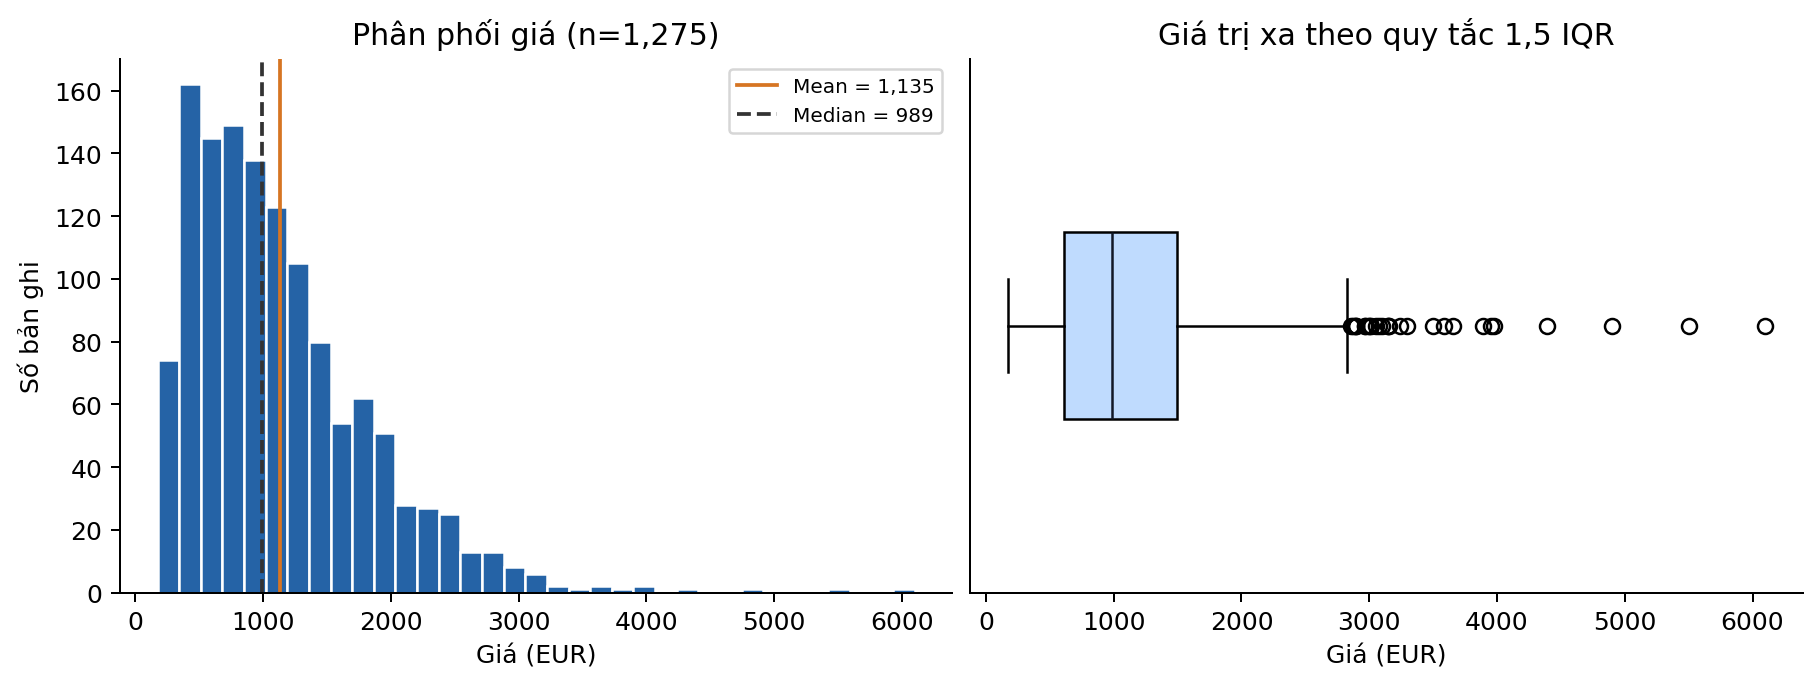

In [11]:
# Hiển thị hình đã tính từ clean
display(Image(filename=str(OUTPUT / 'figures/01_price_distribution.png')))

**Diễn giải:** Giá có phân phối lệch phải: trung bình 1,134.97 EUR cao hơn trung vị 989.00 EUR; hệ số lệch 1.51. Khoảng giữa 50% bản ghi là 609.00-1,496.50 EUR. Có 28 bản ghi vượt ngưỡng IQR trên 2,827.75 EUR; các điểm này được giữ lại vì có thể thuộc phân khúc cao cấp. Trung vị và IQR mô tả mức giá điển hình phù hợp hơn chỉ dùng trung bình.

### Hình 2. RAM và giá

Câu hỏi: RAM và giá có đặc điểm hoặc liên hệ gì trong mẫu?

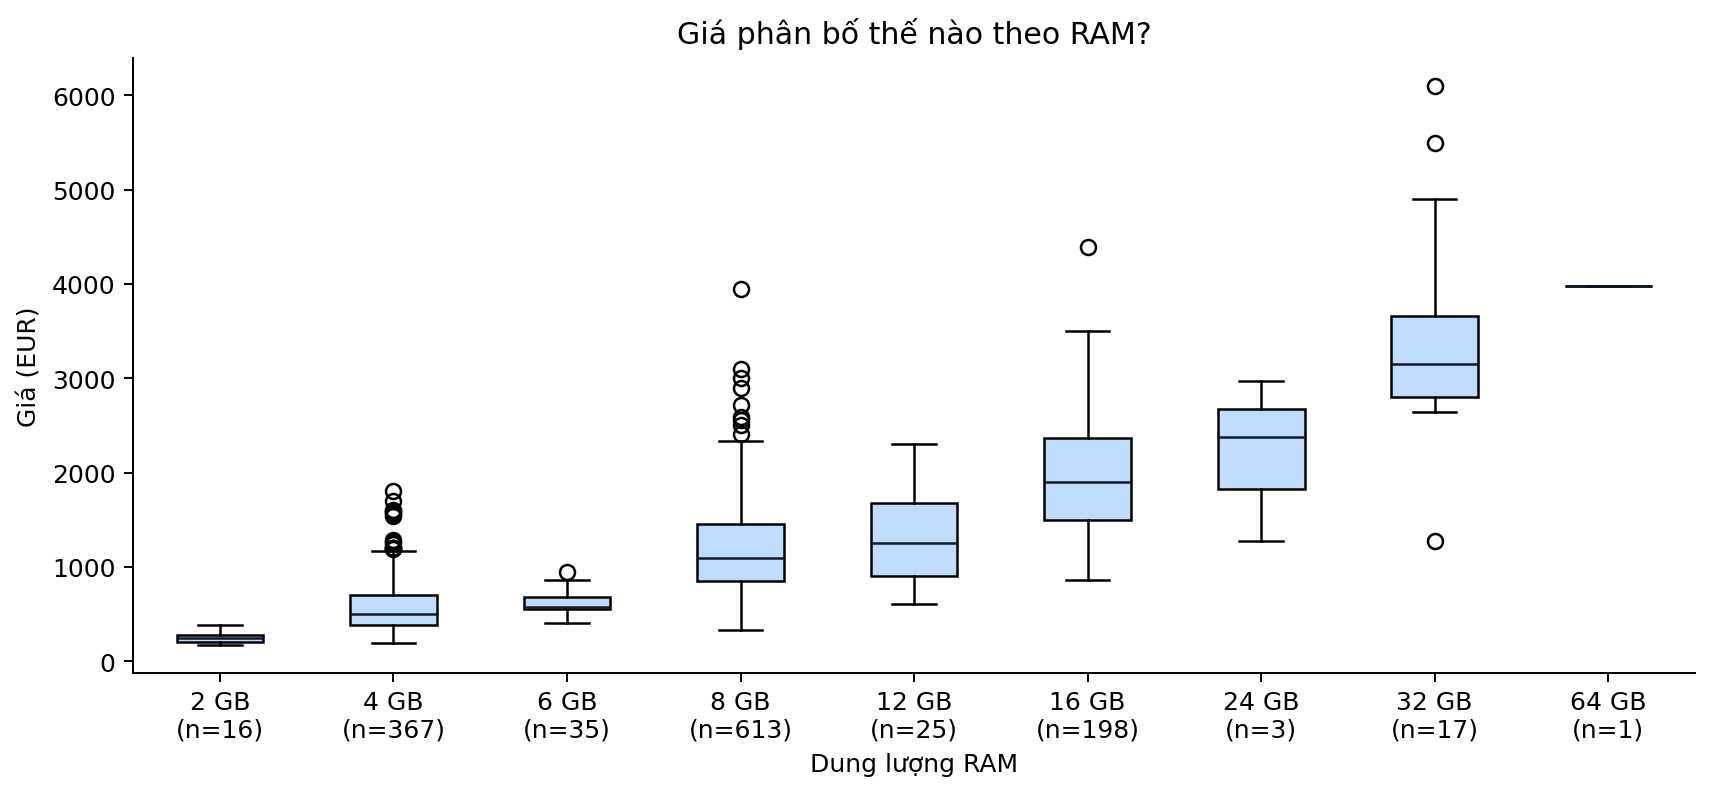

In [12]:
# Hiển thị hình đã tính từ clean
display(Image(filename=str(OUTPUT / 'figures/02_ram_price.png')))

**Diễn giải:** RAM liên hệ đồng biến mạnh với giá trong mẫu (Spearman rho=0.764). Trung vị các nhóm 4 GB, 8 GB và 16 GB lần lượt là 498.00, 1,099.00 và 1,895.00 EUR, với cỡ mẫu tương ứng 367, 613 và 198. Nhóm 24 GB chỉ có 3 bản ghi và 64 GB chỉ có 1 bản ghi, nên không suy rộng xu hướng từ hai nhóm này. Chênh lệch giữa các nhóm không phải mức tăng giá do riêng việc nâng cấp RAM.

### Hình 3. SSD và giá

Câu hỏi: SSD và giá có đặc điểm hoặc liên hệ gì trong mẫu?

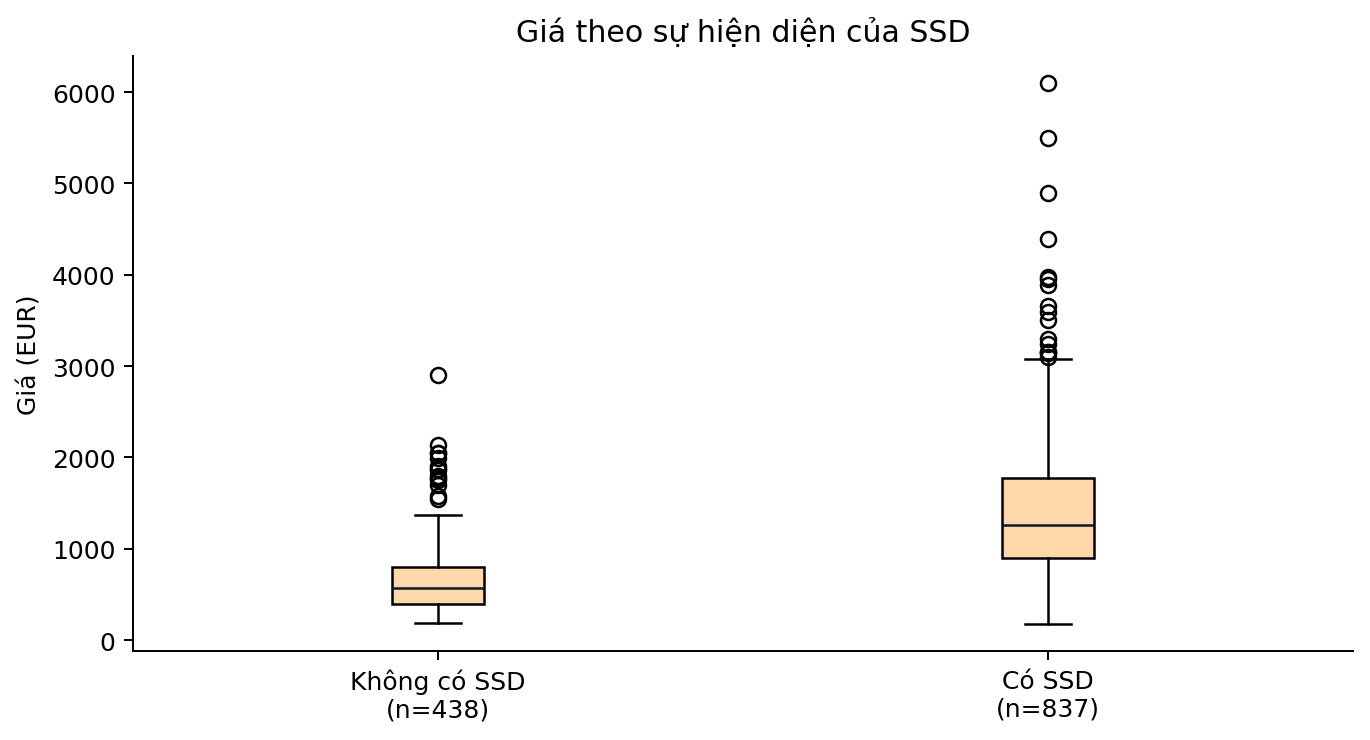

In [13]:
# Hiển thị hình đã tính từ clean
display(Image(filename=str(OUTPUT / 'figures/03_ssd_price.png')))

**Diễn giải:** Nhóm có SSD gồm 837 bản ghi, trung vị 1,265.00 EUR; nhóm không có SSD gồm 438 bản ghi, trung vị 567.00 EUR. Chênh lệch trung vị là 698.00 EUR; khoảng bootstrap phân vị 95% từ 2000 lần lấy mẫu lại là [612.00; 755.50] EUR. Đây là chênh lệch giữa hai nhóm cấu hình, có thể chịu ảnh hưởng của RAM, CPU, hãng và loại máy; không phải chi phí lắp thêm SSD. Flash Storage không được tự gộp vào SSD.

### Hình 4. Loại laptop và giá

Câu hỏi: Loại laptop và giá có đặc điểm hoặc liên hệ gì trong mẫu?

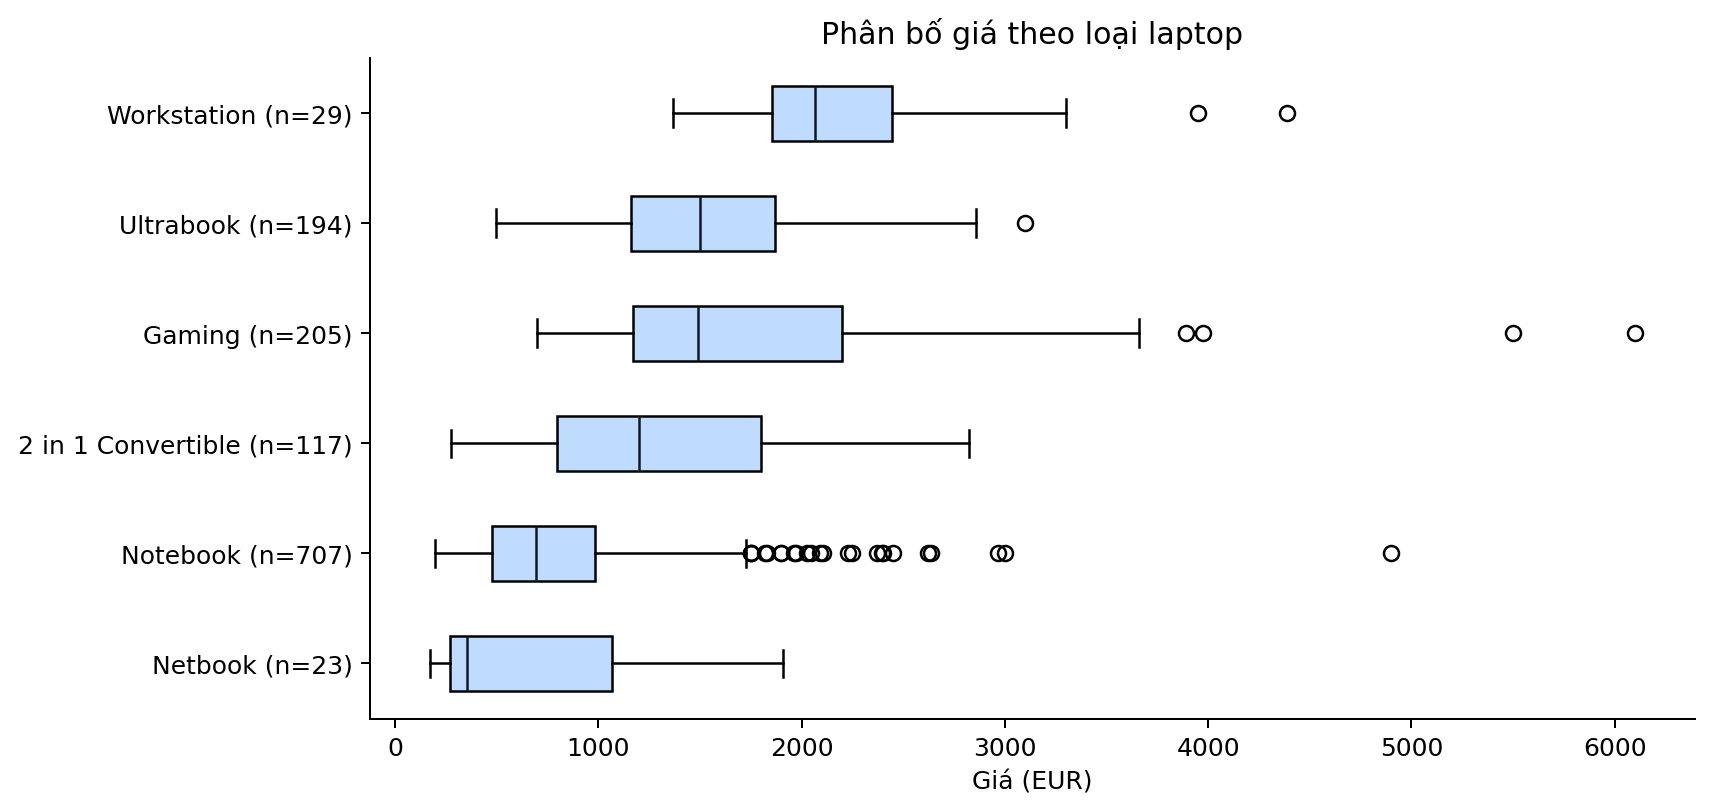

In [14]:
# Hiển thị hình đã tính từ clean
display(Image(filename=str(OUTPUT / 'figures/04_type_price.png')))

**Diễn giải:** Workstation có trung vị 2,064.90 EUR (n=29), Notebook 695.00 EUR (n=707), Netbook 355.00 EUR (n=23). Gaming và Ultrabook có trung vị lần lượt 1,492.80 và 1,499.00 EUR. Phân bố giữa các loại vẫn chồng lấn; loại máy giúp phân đoạn nhu cầu nhưng không quyết định hoàn toàn giá. Kiểm định tổng thể không cho biết cặp loại nào khác biệt có ý nghĩa.

### Hình 5. Hãng và giá

Câu hỏi: Hãng và giá có đặc điểm hoặc liên hệ gì trong mẫu?

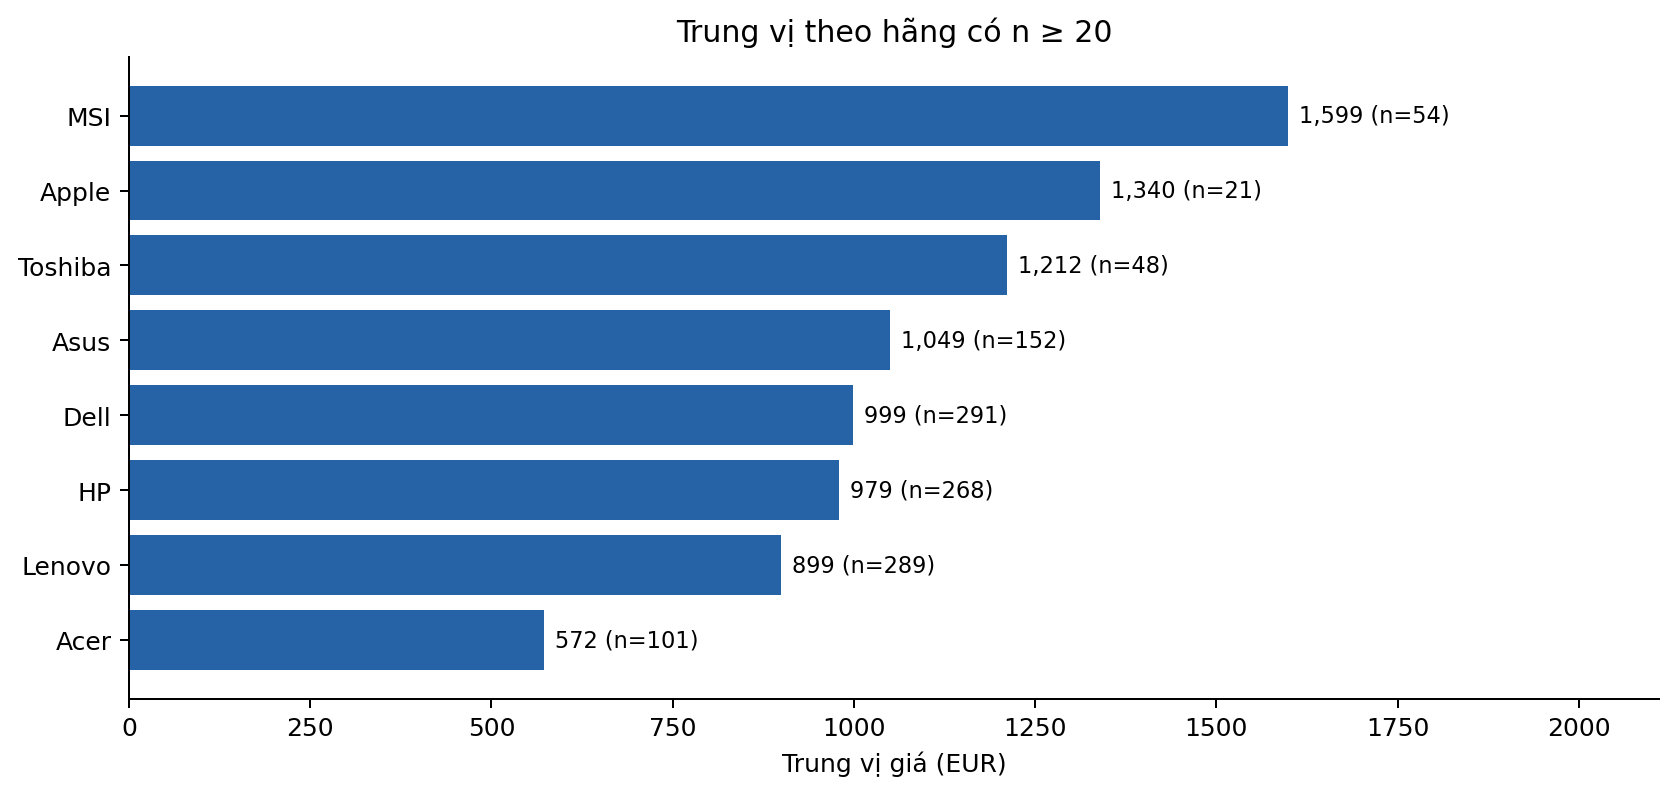

In [15]:
# Hiển thị hình đã tính từ clean
display(Image(filename=str(OUTPUT / 'figures/05_company_price.png')))

**Diễn giải:** Trong các hãng có ít nhất 20 bản ghi, MSI có trung vị 1,599.00 EUR (n=54), Apple 1,339.69 EUR (n=21) và Acer 572.00 EUR (n=101). Ngưỡng n>=20 được chọn để hạn chế diễn giải nhóm quá nhỏ, không phải tiêu chuẩn bảo đảm tính đại diện. Các hãng dưới ngưỡng vẫn được giữ trong dữ liệu và bảng đầy đủ. Đây là so sánh cơ cấu sản phẩm trong mẫu, chưa tách được phần giá gắn với thương hiệu khi cùng cấu hình.

### Hình 6. Mật độ điểm ảnh và giá

Câu hỏi: Mật độ điểm ảnh và giá có đặc điểm hoặc liên hệ gì trong mẫu?

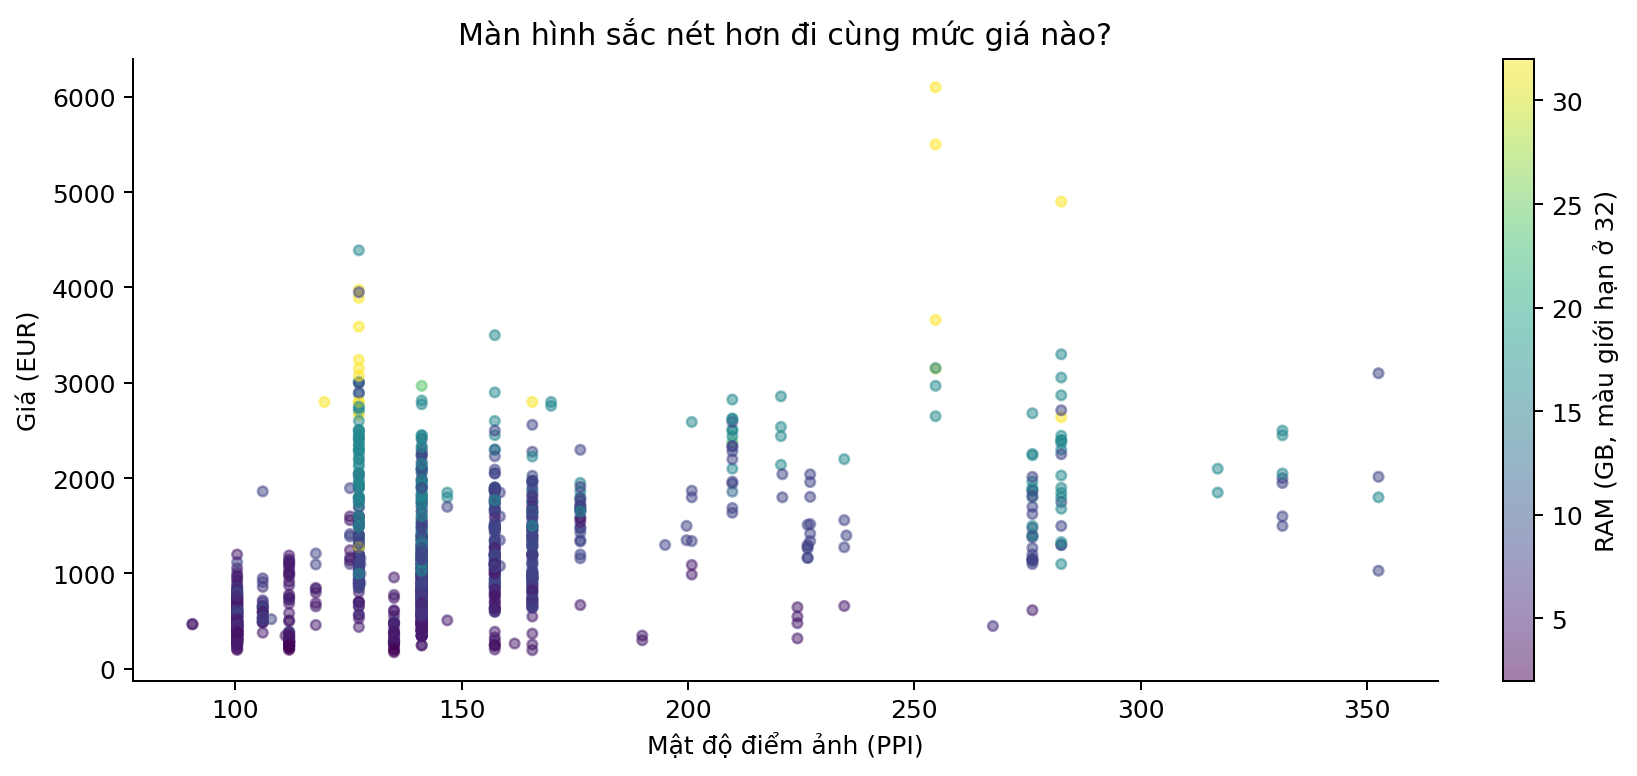

In [16]:
# Hiển thị hình đã tính từ clean
display(Image(filename=str(OUTPUT / 'figures/06_ppi_price.png')))

**Diễn giải:** Mật độ điểm ảnh PPI có liên hệ đồng biến với giá (rho=0.511), nhưng tại cùng PPI giá vẫn phân tán rộng. Màu RAM cho thấy thuộc tính màn hình và cấu hình có thể đi cùng nhau. PPI chỉ phản ánh độ sắc nét theo độ phân giải và kích thước, không đại diện đầy đủ cho chất lượng tấm nền, độ sáng hay độ chính xác màu. Không nên dùng riêng PPI để định giá.

### Hình 7. Tương quan giữa các thuộc tính

Câu hỏi: Tương quan giữa các thuộc tính có đặc điểm hoặc liên hệ gì trong mẫu?

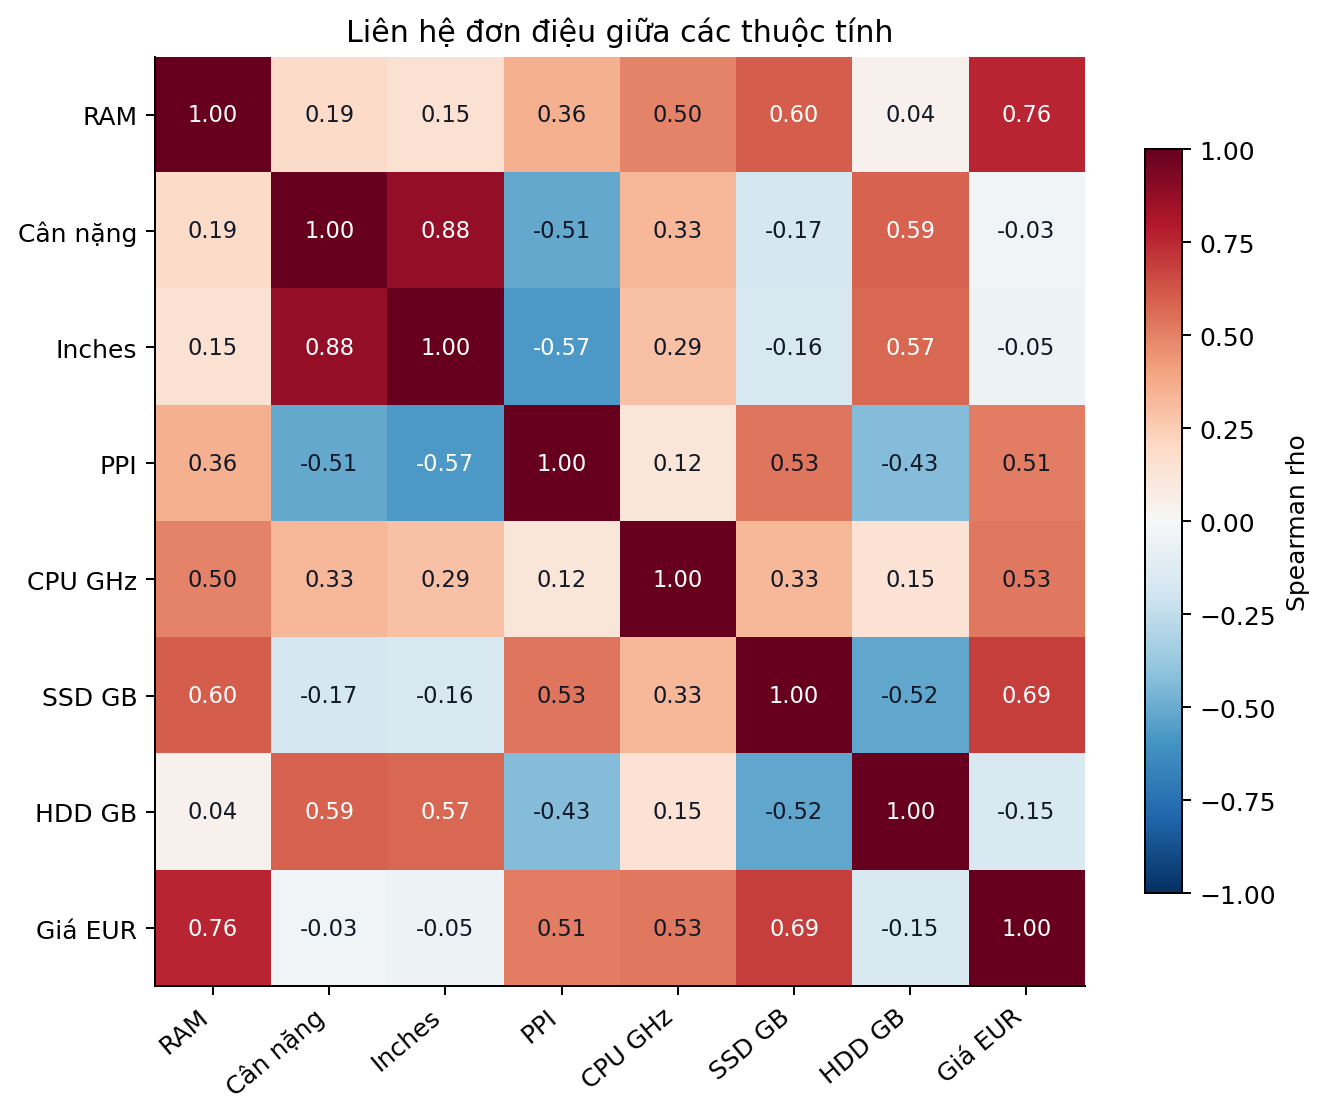

In [17]:
# Hiển thị hình đã tính từ clean
display(Image(filename=str(OUTPUT / 'figures/07_spearman_heatmap.png')))

**Diễn giải:** Trong các biến được đưa vào heatmap, tương quan với giá nổi bật ở RAM (rho=0.764) và SSD_GB (rho=0.689); PPI có rho=0.511. Weight_kg có rho=-0.025, gần 0, nhưng điều này không loại trừ liên hệ phi tuyến hoặc khác biệt trong từng phân khúc. RAM và SSD_GB có rho=0.602, cho thấy các cấu hình thường đi kèm nhau. Cpu_GHz không đo đầy đủ hiệu năng CPU giữa các thế hệ. Các tương quan là mô tả, không chứng minh tác động độc lập hay nhân quả.

### Kiểm định giả thuyết


Chọn mức ý nghĩa alpha=0,05. Do giá lệch phải và RAM là biến rời rạc, dùng kiểm định theo hạng thay vì mặc định phân phối chuẩn. Thực hiện ba kiểm định chính và điều chỉnh p-value bằng Holm cho cả họ kiểm định. Các p-value là xấp xỉ; không diễn giải p-value là xác suất H0 đúng hay là độ lớn tác động.

H1: H0 là rho(RAM, giá)=0; H1 là rho>0. Spearman một phía đo mối liên hệ đơn điệu, xử lý các giá trị RAM bằng nhau qua xếp hạng trung bình. Kết quả rho=0.764 cho thấy liên hệ đồng biến mạnh trong mẫu.

H2: H0 là hai phân phối giá của nhóm có SSD và không SSD giống nhau; H1 là nhóm có SSD có xu hướng giá cao hơn. Mann-Whitney một phía dùng xấp xỉ có hiệu chỉnh ties. U/(n1*n0)=0.864, tức xác suất một bản ghi SSD có giá cao hơn một bản ghi không SSD, cộng nửa xác suất bằng giá, xấp xỉ 86.4% khi lấy ngẫu nhiên từ hai nhóm trong mẫu. Kiểm định này không tự động là kiểm định chênh lệch trung vị khi hình dạng phân phối khác nhau.

H3: H0 là các phân phối giá theo TypeName giống nhau; H1 là có khác biệt ở ít nhất một nhóm. Kruskal-Wallis cho H=545.561 với 6 nhóm; nhóm nhỏ nhất có 23 bản ghi. Chỉ diễn giải như khác biệt về vị trí/trung vị khi các nhóm có hình dạng phân phối tương tự; ở đây kết luận thận trọng về phân phối/thứ hạng. Epsilon-squared H=(H-k+1)/(n-k)=0.426 là chỉ số độ lớn khác biệt tổng thể. Chưa thực hiện hậu kiểm, nên không tuyên bố từng cặp đều khác biệt.

| Giả thuyết | Kiểm định | Thống kê | p gốc | p Holm | Quyết định |
| --- | --- | --- | --- | --- | --- |
| H1 RAM-price | Spearman greater | 0.7642 | 4.651e-245 | 1.395e-244 | Bác bỏ H0 |
| H2 SSD-price | Mann-Whitney greater | 316661.0000 | 1.600e-101 | 1.600e-101 | Bác bỏ H0 |
| H3 type-price | Kruskal-Wallis | 545.5611 | 1.162e-115 | 2.325e-115 | Bác bỏ H0 |

Cả ba H0 đều bị bác bỏ ở alpha=0,05 sau điều chỉnh Holm. Đây là bằng chứng về liên hệ trong mẫu theo giả định các bản ghi độc lập. Cùng một dòng sản phẩm có thể xuất hiện dưới nhiều cấu hình, nên độc lập chỉ là xấp xỉ; mẫu không ngẫu nhiên cũng hạn chế suy rộng ra thị trường. Khoảng bootstrap SSD chỉ phản ánh bất định khi lấy mẫu lại từ dữ liệu hiện có và không bao gồm sai lệch chọn mẫu hoặc biến gây nhiễu.


In [18]:
# Kiểm định ba giả thuyết, hiệu chỉnh Holm và đối chiếu độ nhạy
tests = hypothesis_tests(clean)
display(tests)
sens = sensitivity_analysis(raw, clean)
display(sens)
display(clean[NUMERIC_FEATURES].corr(method='spearman'))


,hypothesis,test,statistic,p_raw,effect,effect_name,p_holm,reject_H0_at_0.05
0,H1 RAM-price,Spearman greater,0.764248,4.650682e-245,0.764248,Spearman rho,1.395205e-244,True
1,H2 SSD-price,Mann-Whitney greater,316661.000000,1.600449e-101,0.863764,P(SSD>non-SSD)+0.5*P(tie),1.600449e-101,True
2,H3 type-price,Kruskal-Wallis,545.561112,1.162464e-115,0.425974,epsilon squared H,2.324929e-115,True


,scenario,n,median_eur,ram_rho,ssd_median_gap_eur,H1_p_holm,H2_p_holm,H3_p_holm
0,raw_with_duplicates,1303,977.0,0.769270,700.900,3.341673e-255,5.400587e-106,3.990274e-118
1,deduplicated_main,1275,989.0,0.764248,698.000,1.395205e-244,1.600449e-101,2.324929e-115
2,without_IQR_flags_sensitivity_only,1247,977.0,0.753011,661.495,2.242619e-228,7.128255e-99,3.174554e-109


,Ram_GB,Weight_kg,Inches,PPI,Cpu_GHz,SSD_GB,HDD_GB,Price_euros
Ram_GB,1.000000,0.189691,0.153507,0.355764,0.496268,0.602106,0.039250,0.764248
Weight_kg,0.189691,1.000000,0.879324,-0.508908,0.329812,-0.173202,0.587395,-0.025026
Inches,0.153507,0.879324,1.000000,-0.572956,0.292475,-0.161478,0.571462,-0.049101
PPI,0.355764,-0.508908,-0.572956,1.000000,0.118076,0.532806,-0.434206,0.511202
Cpu_GHz,0.496268,0.329812,0.292475,0.118076,1.000000,0.329756,0.147622,0.526273
SSD_GB,0.602106,-0.173202,-0.161478,0.532806,0.329756,1.000000,-0.521778,0.688735
HDD_GB,0.039250,0.587395,0.571462,-0.434206,0.147622,-0.521778,1.000000,-0.150580
Price_euros,0.764248,-0.025026,-0.049101,0.511202,0.526273,0.688735,-0.150580,1.000000


### Độ nhạy


| Kịch bản | n | Trung vị EUR | rho RAM-giá | Chênh trung vị SSD EUR |
| --- | --- | --- | --- | --- |
| raw_with_duplicates | 1303 | 977.00 | 0.769 | 700.90 |
| deduplicated_main | 1275 | 989.00 | 0.764 | 698.00 |
| without_IQR_flags_sensitivity_only | 1247 | 977.00 | 0.753 | 661.49 |

Khi giữ bản ghi trùng, bỏ trùng hoặc tạm loại cờ IQR, rho RAM-giá nằm trong khoảng 0.753-0.769, vẫn dương mạnh. Chênh trung vị SSD vẫn dương, khoảng 661.49-700.90 EUR. Cả ba kiểm định vẫn có p Holm<0,05 ở ba kịch bản. Vì vậy hướng kết luận chính không phụ thuộc riêng vào quyết định bỏ trùng hay một số mức giá cao. Kịch bản bỏ cờ IQR chỉ là đối chiếu, không thay thế mẫu chính. Bảng 03_sensitivity.csv lưu cả p-value để kiểm tra lại.


In [19]:
import hashlib, platform
clean.to_csv(OUTPUT / 'laptop_clean.csv', index=False, encoding='utf-8-sig')
schema.to_csv(OUTPUT / 'data_audit.csv', index=False)
tests.to_csv(OUTPUT / 'hypothesis_tests.csv', index=False)
sens.to_csv(OUTPUT / 'sensitivity.csv', index=False)
summary['source_sha256'] = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
summary['versions'] = {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__, 'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__}
(OUTPUT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Hoàn tất. Kết quả tại:', OUTPUT.as_posix())


Hoàn tất. Kết quả tại: laptop_outputs
